# Using the dispatch.particles Python package

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import matplotlib.pyplot as pl
import sys
import os

*Set this to your DISPATCH top:*

In [3]:
top='c:/cygwin64/home/codes/dispatch2/'

Making sure to use the most current DISPATCH version:

In [4]:
sys.path.insert(0,top+'utilities/python')
cwd=top+'experiments/dust/ISM/python'
os.chdir(cwd)

In [5]:
import dispatch
import dispatch.particles

## Reading data from a ``input.nml`` run

In [6]:
p=dispatch.particles.open('../data/rank_00000.pdat',verbose=1);

 2.18 Mp -> 5.23 Mp/s   11 snapshots 207885 particles/snapshot


### Selecting particles with z in a narrow interval

In [7]:
dz=0.001
z0=p.p[:,2,0]
w=np.where(abs(z0)< dz)[0]
print('there are',len(w),'particles in the given z-interval')

there are 118 particles in the given z-interval


#### Plotting their starting points

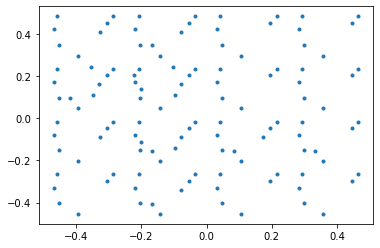

In [8]:
x0=p.p[w,0,0]
y0=p.p[w,1,0]
pl.plot(x0,y0,'.');

#### Plotting their parths in time

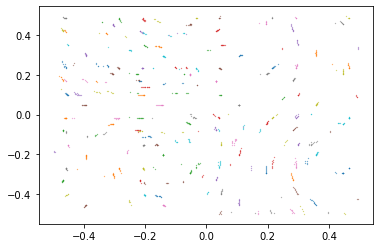

In [9]:
for i in range(len(w)):
    x=p.p[w[i],0,:]
    y=p.p[w[i],1,:]
    pl.plot(x,y,'.',ms=0.5)

#### Plotting paths with one color per bin and marked starting points

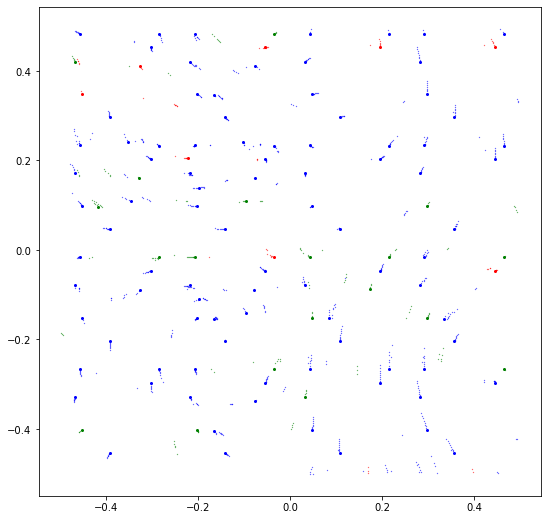

In [10]:
pl.figure(1,figsize=(9,9))
c=['r','g','b']
for bin in range(3):
    z0=p.p[:,2,0]
    w=np.where(np.logical_and(abs(z0)<dz,p.bin==bin))[0]
    for i in range(len(w)):
        x=p.p[w[i],0]
        y=p.p[w[i],1]
        pl.plot(x[0],y[0],'.',c=c[bin],ms=4)
        pl.plot(x,y,'.',c=c[bin],ms=0.5)